# Text Mining Basics: Sephora Moisturizer Reviews

This notebook applies text mining techniques to the cleaned dataset built in `1_Build_Final_Dataset.ipynb` and explored in `2_Data_Exploration.ipynb`.

**Preprocessing**
- Separate cleaning for keyword analysis and for sentiment analysis

**1. Keyword and Frequency Analysis**
- Most common terms in low-rated reviews
- Terms that distinguish low-rated from high-rated reviews
- Terms that distinguish oily-skin from dry-skin reviews

**2. Baseline Sentiment Analysis**
- Lexicon-based sentiment scores compared against star ratings

**3. Topic Modeling**
- Not used, since it overlaps with Claude's complaint labeling that will be used in Phase 3 (explained below)

**4. Plan for Phase 3**
- Analysis path, planned use of Claude with sample prompts, and concerns

## Setup and Data Load

In [1]:
%pip install -q scikit-learn contractions


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# To handle changes to src/utils.py without restarting the kernel
%load_ext autoreload
%autoreload 2           

# Imports
import sys
sys.path.append("..")
from src.preprocessing import preprocess_for_extraction, preprocess_for_sentiment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from src.utils import load_data

In [3]:
# Data load
df = load_data()

# Combine title and text so short complaint titles ("Broke me out!") are included
df["full_text"] = df["review_title"].fillna("") + ". " + df["review_text"]
print(f"Loaded {len(df):,} reviews")

Loaded 184,664 reviews


## Preprocessing

Review text is cleaned in two ways, using functions in `src/preprocessing.py`:
- **For keyword analysis:** HTML and entities removed, text lowercased, contractions expanded ("didn't" → "did not") so negations stay intact, and possessives, numbers, and punctuation removed.
- **For sentiment analysis:** only HTML, quote styles, and spacing are fixed. Capitalization, punctuation, and emojis are kept because VADER uses them to judge intensity ("LOVE it!!!" scores higher than "love it").

The check below shows how common each formatting issue is in this dataset.

In [4]:
# Check what actually needs cleaning
checks = {
    "HTML tags": r"<[^>]+>",
    "HTML entities (&amp; etc.)": r"&[a-z]+;|&#\d+;",
    "URLs": r"https?://|www\.",
    "Curly apostrophes": r"[\u2018\u2019]",
    "Missing space after punctuation": r"[.!?][A-Za-z]",
}
for name, pattern in checks.items():
    print(f"{name}: {df['full_text'].str.contains(pattern, regex=True).mean():.2%} of reviews")

HTML tags: 0.00% of reviews
HTML entities (&amp; etc.): 0.00% of reviews
URLs: 0.01% of reviews
Curly apostrophes: 63.32% of reviews
Missing space after punctuation: 6.81% of reviews


In [5]:
# Apply the preprocessing function to clean the text for keyword extraction 
df["clean_text"] = df["full_text"].apply(preprocess_for_extraction)

example = df.sample(1, random_state=1)
print("Original:\n", example["full_text"].iloc[0], "\n")
print("Cleaned for keywords:\n", example["clean_text"].iloc[0])

Original:
 . When I tell you this stuff is amazing, it is AMAZING. I absolutely am in love with this Moisturizing sorbet. It smells wonderful, and leaves my skin feeling so smooth, hydrated. And refreshed. I will absolutely be purchasing this product again! 

Cleaned for keywords:
 when i tell you this stuff is amazing it is amazing i absolutely am in love with this moisturizing sorbet it smells wonderful and leaves my skin feeling so smooth hydrated and refreshed i will absolutely be purchasing this product again


**Observations**

- HTML and URLs are essentially absent (0% and 0.01% of reviews), so those steps act as safeguards rather than meaningful fixes.
- Curly apostrophes appear in 63% of reviews, making quote normalization the most important cleaning step. Without it, contractions like "didn’t" would not be expanded, and the keyword analysis would show fragments like "didn" instead of "did not."
- 6.8% of reviews are missing a space after punctuation like "great.Love it". Without a fix, the two words would merge into one token once punctuation is removed.

## 1. Keyword and Frequency Analysis

**Approach:** Terms are measured as the share of reviews that contain them rather than raw counts, so one long review repeating a word doesn't skew results. Both single words and two-word phrases are included, since phrases like "broke out" or "not moisturizing" carry more meaning than single words. 

In the oily vs. dry comparison, "oily" and "dry" have the largest gaps, partly because reviewers use them to describe their own skin ("I have dry skin"). Removing them was considered but not done, because the same words also describe what a product did ("this left my skin dry," "I felt oily all day"), and no simple rule reliably separates the two uses. Removing the words, or phrases like "dry skin," would also discard real complaints. They are kept, with the understanding that their gaps mix self-description and complaints, so the analysis focuses on the other terms in the comparison.

Standard English stopwords are removed, except negations ("not," "no," "never"), which change a phrase's meaning in reviews. Words that appear in nearly every review regardless of opinion ("skin," "moisturizer," "product") are also removed.

To keep processing fast, each comparison group is capped at a random sample of 30,000 reviews. At that size, term shares are estimated precisely.

In [6]:
# Setting up the customized stop word list. We want to keep negations, and add some domain-specific words that are not informative for our analysis.
negations = {"not", "no", "nor", "never", "cannot"}
domain_words = {"skin", "face", "moisturizer", "moisturizers", "product", "products",
                "cream", "creams", "use", "used", "using", "just", "really"}
cust_stopwords = list((ENGLISH_STOP_WORDS - negations) | domain_words)

max_per_group = 30000

# Function to randomly sample reviews if there are more than 30,000 reviews in a group. This is to avoid having one group dominate the analysis.
def cap_sample(texts, n=max_per_group, seed=42):
    """If there are more than n reviews, randomly pick n of them (each review stays complete)."""
    return texts.sample(n=min(n, len(texts)), random_state=seed)

# Function to compute the percent of reviews containing each term (words and two-word phrases).
def term_shares(texts, ngram_range=(1, 2), min_df=30):
    """Percent of reviews containing each term (words and two-word phrases)."""
    vec = CountVectorizer(stop_words=cust_stopwords, ngram_range=ngram_range,
                          min_df=min_df, binary=True)
    X = vec.fit_transform(texts)
    shares = np.asarray(X.mean(axis=0)).ravel() * 100
    return pd.Series(shares, index=vec.get_feature_names_out()).sort_values(ascending=False)

# Function to compare the percent of reviews containing each term in two groups, and the gap in percentage points.
def compare_terms(texts_a, texts_b, label_a, label_b, ngram_range=(1, 2), min_df=30):
    """Percent of reviews containing each term in two groups, and the gap in percentage points."""
    vec = CountVectorizer(stop_words=cust_stopwords, ngram_range=ngram_range,
                          min_df=min_df, binary=True)
    X = vec.fit_transform(pd.concat([texts_a, texts_b]))
    n_a = len(texts_a)
    share_a = np.asarray(X[:n_a].mean(axis=0)).ravel() * 100
    share_b = np.asarray(X[n_a:].mean(axis=0)).ravel() * 100
    out = pd.DataFrame({label_a: share_a, label_b: share_b}, index=vec.get_feature_names_out())
    out["gap_pts"] = out[label_a] - out[label_b]
    return out.round(2)

# Function to plot a horizontal bar chart of terms, largest at the top.
def plot_terms(series, title, xlabel="% of reviews containing term"):
    """Horizontal bar chart of terms, largest at the top."""
    ax = series.sort_values().plot(kind="barh", color="#4C72B0", figsize=(7, 5))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [7]:
# Define the rating groups for analysis
low = df[df["rating"] <= 2]
high = df[df["rating"] >= 4]
print(f"Low-rated (1-2 stars): {len(low):,} reviews ({len(low)/len(df):.1%})")
print(f"High-rated (4-5 stars): {len(high):,} reviews ({len(high)/len(df):.1%})")

Low-rated (1-2 stars): 17,143 reviews (9.3%)
High-rated (4-5 stars): 153,384 reviews (83.1%)


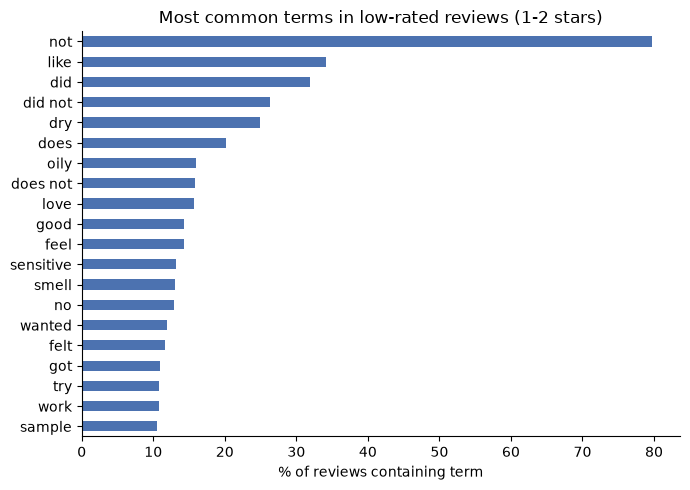

In [8]:
# Find the most common terms in low-rated reviews (1-2 stars)
low_terms = term_shares(cap_sample(low["clean_text"]))
plot_terms(low_terms.head(20), "Most common terms in low-rated reviews (1-2 stars)")

More common in low-rated reviews:


,low_rated_pct,high_rated_pct,gap_pts
not,79.65,51.59,28.06
did,31.84,12.43,19.42
did not,26.35,8.85,17.51
wanted,11.96,1.15,10.81
broke,9.07,0.36,8.71
like,34.19,25.80,8.39
work,10.79,2.91,7.88
disappointed,7.88,0.57,7.31
bad,8.99,1.92,7.07
wanted love,6.29,0.05,6.24


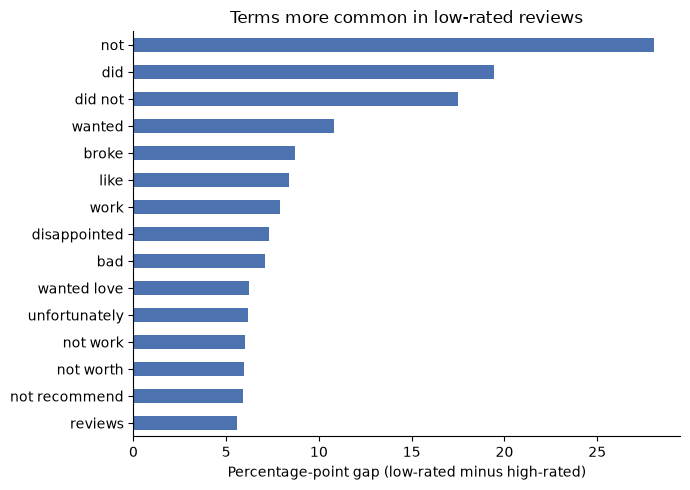

More common in high-rated reviews:


,low_rated_pct,high_rated_pct,gap_pts
love,15.76,40.25,-24.49
great,9.93,25.52,-15.59
amazing,2.88,15.96,-13.08
soft,2.02,14.09,-12.07
hydrated,2.60,13.82,-11.22
smooth,2.22,12.07,-9.85
light,3.86,13.53,-9.67
feels,10.16,18.79,-8.64
perfect,1.29,9.62,-8.32
definitely,6.38,14.63,-8.25


In [9]:
# Find the terms that are more common in low-rated reviews than high-rated reviews, and vice versa
rating_gap = compare_terms(cap_sample(low["clean_text"]), cap_sample(high["clean_text"]),
                           "low_rated_pct", "high_rated_pct")

print("More common in low-rated reviews:")
display(rating_gap.sort_values("gap_pts", ascending=False).head(15))
plot_terms(rating_gap["gap_pts"].nlargest(15),
           "Terms more common in low-rated reviews",
           "Percentage-point gap (low-rated minus high-rated)")

print("More common in high-rated reviews:")
display(rating_gap.sort_values("gap_pts").head(15))

1-3 star reviews: oily 3,685 | dry 6,844


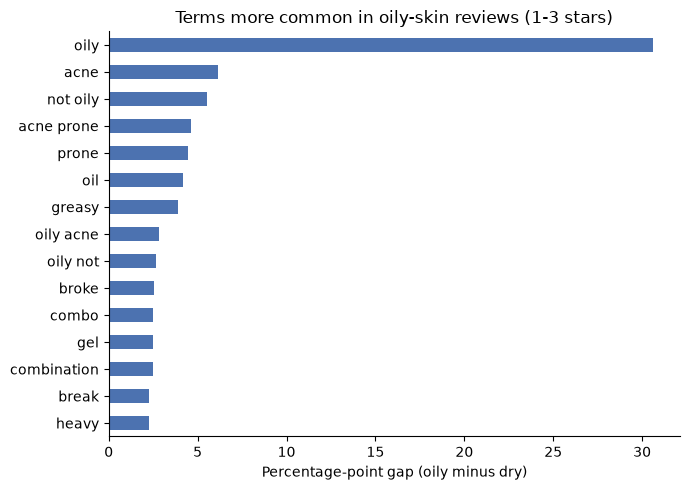

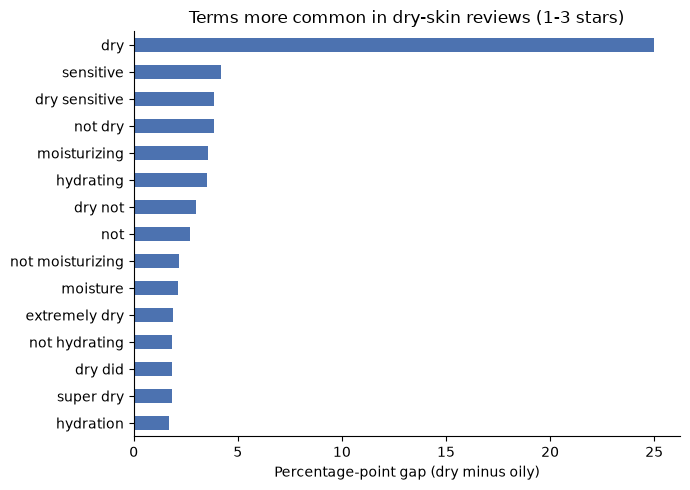

In [10]:
# Find the terms that are more common in oily-skin reviews than dry-skin reviews, and vice versa, among low-rated reviews

# Reviews rated 1-3 stars, where complaints are concentrated (3-star reviews are often mixed)
unhappy = df[df["rating"] <= 3]
oily = unhappy.loc[unhappy["skin_type"] == "oily", "clean_text"]
dry = unhappy.loc[unhappy["skin_type"] == "dry", "clean_text"]
print(f"1-3 star reviews: oily {len(oily):,} | dry {len(dry):,}")

skin_gap = compare_terms(oily, dry, "oily_pct", "dry_pct")

plot_terms(skin_gap["gap_pts"].nlargest(15),
           "Terms more common in oily-skin reviews (1-3 stars)",
           "Percentage-point gap (oily minus dry)")
plot_terms((-skin_gap["gap_pts"]).nlargest(15),
           "Terms more common in dry-skin reviews (1-3 stars)",
           "Percentage-point gap (dry minus oily)")

**Observations**

- Only 9.3% of reviews (17,143) are rated 1–2 stars, while 83.1% are rated 4–5 stars. Complaints are therefore a small share of the text, which is why the comparisons above measure the share of reviews containing a term within each group rather than raw counts.
- After contractions are expanded, "not" appears in 80% of 1–2 star reviews, with "did not" in 26% and "does not" in about 16%. The most frequent terms are otherwise general ("like," "love," "good," "feel"). Skin-related words do appear: "dry" (25%), "oily" (16%), "sensitive" (13%), and "smell" (13%). Frequency alone mostly shows how reviewers express disappointment rather than what went wrong.
- The clearest complaint signals are "broke" (as in "broke me out"), in 9.1% of low-rated vs. 0.4% of high-rated reviews; "not work" (6.5% vs. 0.5%); "not recommend" (6.4% vs. 0.5%); and "not worth" (6.1% vs. 0.1%). Disappointment language is also distinctive: "wanted love" (from "wanted to love it," 6.3% vs. 0.05%), "unfortunately," and "disappointed." "Reviews" is also more common in low-rated reviews (7.0% vs. 1.4%), likely from reviewers who bought a product based on its reviews and were let down. High-rated reviews describe how the product feels: "soft," "hydrated," "smooth," and "light" each appear in 12–14% of high-rated reviews vs. 2–4% of low-rated ones.
- Among 1–3 star reviews (3,685 oily, 6,844 dry), "oily" and "dry" show by far the largest gaps (about 30 and 25 percentage points). As noted in the approach, these mix reviewers describing their own skin with complaints about results, so they aren't interpreted on their own. The remaining terms are more informative. Oily-skin reviews more often mention acne and breakouts ("acne," "acne prone," "broke," "break"), greasiness ("greasy," "oil," "heavy"), and gel textures. Dry-skin reviews more often mention a lack of moisture ("not moisturizing," "not hydrating," "extremely dry") and sensitivity ("sensitive," "dry sensitive"). This matches the expected pattern: heavy textures disappoint oily skin, and products that don't moisturize enough disappoint dry skin.
- "Not" appears in 52% of high-rated reviews too, often as praise ("not greasy," "does not break me out"), and "not oily" and "not dry" could be praise or reviewers describing their own skin. Because stopwords are removed before phrases are formed, some phrases also join words that weren't next to each other ("wanted to love it" becomes "wanted love"; phrases like "oily not" and "dry did" are similar artifacts). Single words and phrases also can't show how many distinct complaints a review contains. These limits are why Phase 3 uses Claude to label complaints in context rather than relying on keyword counts.
- **Implications for Phase 3:** The terms above suggest a starting set of complaint categories: greasy/heavy, breakouts, not moisturizing enough, irritation/sensitivity, fragrance/smell, not worth the price, and no results ("not work"). Claude's suggestions on a sample of reviews will refine this list.

---

## 2. Baseline Sentiment Analysis

**Approach:** VADER, a lexicon-based sentiment tool, scores each review from -1 (most negative) to +1 (most positive). Scores are compared against star ratings, and reviews where the two disagree are examined to see how well a general-purpose sentiment tool handles skincare language.

VADER is run on a random sample of 50,000 reviews (27% of the dataset) to keep run time short; at this size, averages by rating are estimated precisely. Following VADER's standard thresholds, scores of 0.05 or above are labeled positive and -0.05 or below negative. Scores in between are labeled as near zero rather than neutral since they don't necessarily mean the reviewer felt neutral, only that VADER found no clear lean, either because positive and negative words offset each other (as in a mixed review) or because the review's wording isn't in VADER's lexicon (common for skincare terms like "broke me out" or "pilled").

In [11]:
%pip install -q vaderSentiment


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
# Imports
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from src.utils import plot_bar

In [13]:
# Helper functions for sentiment analysis using VADER
analyzer = SentimentIntensityAnalyzer()

# Calculate VADER sentiment scores for a series of texts
def vader_scores(texts):
    """VADER compound score for each review, from -1 (negative) to +1 (positive)."""
    return texts.apply(lambda t: analyzer.polarity_scores(t)["compound"])

# Convert compound scores to positive / near zero / negative using VADER's standard cutoffs
def sentiment_label(scores, threshold=0.05):
    """Convert compound scores to positive / near zero / negative using VADER's standard cutoffs."""
    return pd.Series(np.select([scores >= threshold, scores <= -threshold],
                               ["positive", "negative"], default="near zero"),
                     index=scores.index)

# Check the distribution of the star ratings in the dataset
def rating_group(ratings):
    """Group star ratings into low (1-2), mid (3), and high (4-5)."""
    return pd.cut(ratings, bins=[0, 2, 3, 5], labels=["low (1-2)", "mid (3)", "high (4-5)"])

In [14]:
# Apply preprocessing and score a random sample of 50,000 reviews with VADER
sent = df.sample(n=50000, random_state=42).copy()
sent["sentiment_text"] = sent["full_text"].apply(preprocess_for_sentiment)
sent["vader"] = vader_scores(sent["sentiment_text"])
sent["vader_label"] = sentiment_label(sent["vader"])
sent["rating_group"] = rating_group(sent["rating"])

print(f"Scored {len(sent):,} reviews")
print(sent["vader"].describe().round(3))

Scored 50,000 reviews
count    50000.000
mean         0.731
std          0.397
min         -0.982
25%          0.715
50%          0.897
75%          0.955
max          0.999
Name: vader, dtype: float64


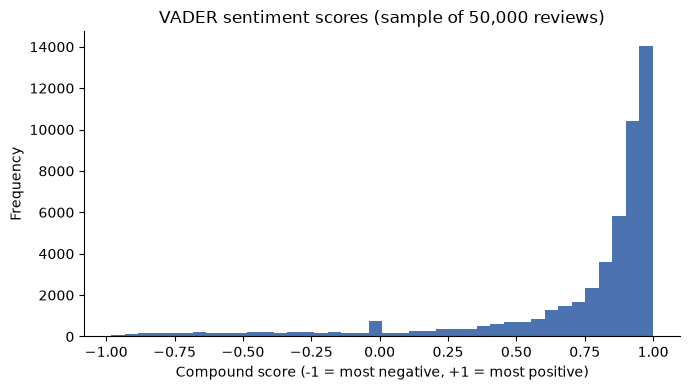

In [15]:
# Plot the distribution of VADER compound scores
ax = sent["vader"].plot(kind="hist", bins=40, color="#4C72B0", figsize=(7, 4))
ax.set_title("VADER sentiment scores (sample of 50,000 reviews)")
ax.set_xlabel("Compound score (-1 = most negative, +1 = most positive)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

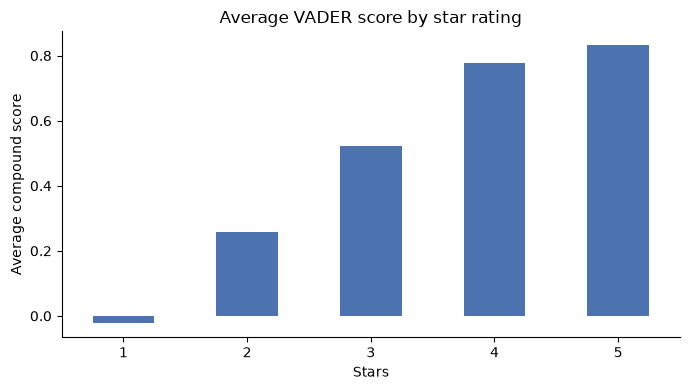

Rank correlation between VADER score and rating: 0.36

VADER label within each rating group (% of reviews, rows sum to 100):


vader_label,near zero,negative,positive
rating_group,,,
low (1-2),5.3,39.8,54.8
mid (3),3.0,15.6,81.4
high (4-5),1.2,2.2,96.6


In [16]:
# Plot the average VADER score by star rating
plot_bar(sent.groupby("rating")["vader"].mean().round(3),
         "Average VADER score by star rating", "Stars", "Average compound score")

print(f"Rank correlation between VADER score and rating: "
      f"{sent['vader'].corr(sent['rating'], method='spearman'):.2f}")

print("\nVADER label within each rating group (% of reviews, rows sum to 100):")
(pd.crosstab(sent["rating_group"], sent["vader_label"], normalize="index") * 100).round(1)

In [17]:
# Where do the discrepancies between star ratings and VADER scores occur?
# Show examples of low-rated reviews that VADER scores as positive, and high-rated reviews that VADER scores as negative.
pd.set_option("display.max_colwidth", 400)
cols = ["rating", "skin_type", "vader", "full_text"]

low_but_positive = sent[(sent["rating"] <= 2) & (sent["vader_label"] == "positive")]
high_but_negative = sent[(sent["rating"] >= 4) & (sent["vader_label"] == "negative")]

print(f"Low-rated reviews VADER scores as positive: {len(low_but_positive):,} "
      f"({len(low_but_positive) / (sent['rating'] <= 2).sum():.1%} of low-rated)")
display(low_but_positive.sample(5, random_state=42)[cols])

print(f"High-rated reviews VADER scores as negative: {len(high_but_negative):,} "
      f"({len(high_but_negative) / (sent['rating'] >= 4).sum():.1%} of high-rated)")
display(high_but_negative.sample(5, random_state=42)[cols])

Low-rated reviews VADER scores as positive: 2,569 (54.8% of low-rated)


,rating,skin_type,vader,full_text
146762,2,combination,0.1708,Pilled so bad.. I love my Caudalie night cream and expected to love this for daytime. It pilled so bad that I only used it once! Do not even try to wear this with other skincare products or makeup.
104011,1,combination,0.3818,"Felt like a primer.. I bought this because it was recommended for my skin type. (Combo). It is not moisturizing at all. It has the velvety texture as a primer, not a moisturizer. The ingredient list is similar to some primers as well. Returned it after one use as it seemed to be a waste of money."
90762,1,combination,0.6757,no results after a week.. I have been using this product for a week and half and have not seen a difference. I have pretty significant hyperpigmentation on my cheeks and forehead from having children for the last 12 years. Nothing I’ve used in the past OTC seems to help. I was hoping this would work from all the glowing reviews. I’ve also seen no difference to my acne scars/pigmentation. Still...
132039,1,combination,0.1901,. Literally nothing has changed on my face Like it didn’t do anything I know face products can’t make your face change a lot but this didn’t do anything
75773,1,normal,0.3612,. Cause my face to turn red and ruddy; felt like a had a mild sunburn for about 5 days.


High-rated reviews VADER scores as negative: 908 (2.2% of high-rated)


,rating,skin_type,vader,full_text
125866,5,combination,-0.2671,"Goodbye, expensive moisturizers. Hello First Aid!. Here’s the thing - I love the idea of a fancy moisturizer (that most likely costs $50+) but that’s completely unnecessary. This moisturizer is legit. It’s the one moisturizer I find myself reaching for time and time again, not only because it’s inexpensive but because it will repair even my most damaged, dry skin in NYC winters!"
135419,5,dry,-0.6582,BUY IT NOW. The holy grail of moisturizers!! I struggled with finding a moisturizer that moisturized my skin without being too heavy until I found this product. Could not recommend this enough!
64330,5,normal,-0.6049,. Super surprised that I’ve seen some negative comments. I have so many Different types of moisturizers my daughter asked me if I had gotten Botox. Yes it does come In a small container So possible to tell you this really does work and it has actually took out some lines on the sides of my eyes. At the time I was using Shishido . However when I started using this moisturizer I was thinking thi...
69957,5,oily,-0.0649,"worth it. I have oily, acne-prone skin and usually avoid chemical sunscreens for this reason. This doesn’t break me out and doesn’t leave an ashy cast. I can wear it alone or under makeup. Worth the price for me and replaced my matte physical sunscreen from another brand."
45324,5,combination,-0.4912,"This is the best night cream out there.. It’s super moisturizing, isn’t full of toxic stuff, and smells great. I use it at night and also sometimes after I’ve been in the sun/wind/cold. It takes a little while to absorb but since I’m usually asleep I don’t care. And the price! I’m pretty liberal with this stuff and a jar will last me about a year. My last two boyfriends have gotten hooked on t..."


**Observations**

- The median VADER score is 0.90 (mean 0.73), and most reviews cluster near +1, matching the positive skew of star ratings. The small spike at 0 reflects reviews where VADER found no clear lean.
- Average scores rise with star rating, from about 0 at 1 star to about 0.26 at 2 stars, 0.52 at 3 stars, and 0.83 at 5 stars. However, the rank correlation with rating is only 0.36, so individual scores often don't match the reviewer's stated satisfaction.
- VADER scores 54.8% of low-rated (1–2 star) reviews as positive and only 39.8% as negative. By contrast, 96.6% of high-rated reviews score positive and only 2.2% negative. VADER reliably recognizes happy reviewers but not unhappy ones.

The disagreements show recurring patterns specific to skincare reviews:
  - Reviewers describe what they expected or compare to products they like ("I love my Caudalie night cream and expected to love this… it pilled so bad"), or reference other reviews ("I was hoping this would work from all the glowing reviews").
  - Terms like "pilled", "red and ruddy", "felt like a mild sunburn", and "not moisturizing at all" describe clear product failures, but VADER doesn't treat them as negative.
  - High-rated reviews are scored negative because they mention problems the product avoided or solved ("doesn't break me out," "could not recommend this enough," "repair even my most damaged, dry skin").

**What this means for Phase 3:** Sentiment adds little beyond the star rating, which already measures satisfaction directly, and where the two disagree, the rating is usually right. Sentiment scores are therefore not used in Phase 3. The rating serves as the satisfaction measure, and Claude labels the specific complaints in context, which handles expectations, comparisons, negation, and skincare-specific wording that a general lexicon misses.

---

## 3. Topic Modeling: Not Used

Topic modeling would overlap with the Phase 3 approach, where Claude labels each review with one or more complaint categories (or "no complaint"). Claude's labels are more precise for this problem: reviews are short and informal, which tends to produce vague LDA topics, and a review can contain several distinct complaints. Complaint categories are instead drafted from Claude's suggestions on a sample of reviews (Section 4) and checked against the keyword analysis above.

## 4. Plan for Phase 3

### Analysis Path: B (Understanding/Extraction)

The goal is to understand which complaints reviewers have about specific moisturizers and how those complaints differ by skin type, not to predict an outcome. The dataset has no target variable, and the star rating doesn't need predicting since every review already has one.

The data supports a product-by-skin-type comparison as the core analysis:
- Shoppers already sort themselves by skin type (notebook 2): oil-free gels draw mostly oily-skin reviewers, and rich creams draw mostly dry-skin reviewers. Comparing complaint rates across different products would mix up product differences with who buys them, so the analysis compares skin types within the same product.
- Enough data exists for this comparison: 130 moisturizers have at least 30 reviews from every skin type (notebook 01).
- Skin types are imbalanced (54.5% combination, 11.2% oily), so results are reported as complaint rates within each skin type rather than counts.

This produces findings that translate directly into rules for Sephora's skincare quiz, such as "Product X draws greasy complaints from 28% of oily-skin reviewers vs. 4% of dry-skin reviewers, so the quiz should not recommend it for oily skin."

**Scope:** The 20 most-reviewed eligible moisturizers (excluding one that doubles as a makeup primer), with a stratified sample of 100 reviews per product per skin type: 8,000 reviews in total. Reviews of all ratings are included, since keyword and sentiment analysis showed that mixed 3- and 4-star reviews contain complaints too.

**Not in Scope:**
- Sentiment scores: VADER tracked star ratings only weakly and missed most complaints (Section 2), so the star rating serves as the satisfaction measure.
- Ingredient comparisons: Products with and without a given ingredient (e.g., fragrance) also differ in brand, price, and texture, so a fair comparison would require carefully matched products. This is left out of the core analysis to keep scope manageable.

### Planned Use of Claude

Claude will label every review in the 8,000-review sample with the complaints it contains:
- A review can have several complaints or none ("no complaint" is a valid label), since many reviews are mixed.
- Only problems the reviewer experienced with this product count. Problems a product avoided ("doesn't break me out"), problems with other products the reviewer compares it to, and the reviewer describing their own skin type are not complaints. These are exactly the cases where keyword counts and VADER failed (Sections 1–2).
- Labels are returned as JSON so they can be turned directly into complaint rates.

Labeling runs through the Batch API with Claude's lowest-cost model. A random sample of about 100 labeled reviews will be hand-checked to measure agreement with Claude before computing results.

The sample prompts below test two steps: (1) asking Claude to suggest complaint categories from a sample of reviews, and (2) labeling a small set of reviews with those categories.

In [18]:
%pip install -q anthropic python-dotenv


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
import json
import anthropic
from dotenv import load_dotenv

RUN_CLAUDE = False   # set to True once I get a working API key

load_dotenv("../.env", override=True)   # reads ANTHROPIC_API_KEY from the project folder
client = anthropic.Anthropic()
MODEL = "claude-haiku-5-5"              # lowest-cost Claude model


def ask_claude(prompt, system=None, max_tokens=1500):
    """Send one prompt to Claude and return the text reply.
    Temperature 0 keeps replies consistent when the same review is labeled again."""
    kwargs = {"model": MODEL, "max_tokens": max_tokens, "temperature": 0,
              "messages": [{"role": "user", "content": prompt}]}
    if system:
        kwargs["system"] = system
    response = client.messages.create(**kwargs)
    return response.content[0].text

In [20]:
# Sample prompt 1 - suggest complaint categories
# 40 reviews rated 1-3 stars, 10 per skin type. Only review text is sent (no reviewer IDs).
discovery = (df[df["rating"] <= 3]
             .groupby("skin_type")
             .sample(10, random_state=7))
numbered = "\n".join(f"{i+1}. {t}" for i, t in enumerate(discovery["full_text"]))

discovery_prompt = f"""Below are {len(discovery)} customer reviews of facial moisturizers from Sephora.

Identify the main types of complaints reviewers make about the products. Suggest 8 to 10
complaint categories that together cover most complaints. For each category, give:
- a short name in lowercase with underscores instead of spaces (e.g., greasy_heavy)
- a one-sentence definition
- one example phrase quoted from the reviews

Only include problems with the product itself, not reviewers describing their own skin.

Reviews:
{numbered}"""

if RUN_CLAUDE:
    print(ask_claude(discovery_prompt))
else:
    print("Claude calls are switched off (RUN_CLAUDE = False). Prompt prepared:\n")
    print(discovery_prompt[:1200], "...")

Claude calls are switched off (RUN_CLAUDE = False). Prompt prepared:

Below are 40 customer reviews of facial moisturizers from Sephora.

Identify the main types of complaints reviewers make about the products. Suggest 8 to 10
complaint categories that together cover most complaints. For each category, give:
- a short name in lowercase with underscores instead of spaces (e.g., greasy_heavy)
- a one-sentence definition
- one example phrase quoted from the reviews

Only include problems with the product itself, not reviewers describing their own skin.

Reviews:
1. Didnt work AT ALL. This did absolutely NOTHING for my feet and dare I say somehow made them dryer?? I don’t know what happened and if I got a bad batch or something but it was a complete waste of money and the only thing that been a complete total failure I’ve tried from this company
2. Better as a daytime cream for me!. My favorite things about this cream is that 1.) it’s easy to distribute on my skin, 2.) no heavy fragrance, 

In [21]:
# Draft categories based on the keyword analysis from Section 1; to be refined with sample prompt 1
CATEGORIES = {
    "greasy_heavy": "Feels greasy, oily, heavy, or sits on top of the skin without absorbing",
    "breakouts": "Caused acne, breakouts, clogged pores, or bumps",
    "not_moisturizing": "Not moisturizing or hydrating enough; skin still felt dry or tight",
    "irritation": "Caused redness, stinging, burning, itching, or a reaction",
    "fragrance": "Unpleasant or too-strong scent",
    "pilling_texture": "Pills, balls up, feels sticky, or doesn't layer well with makeup or other products",
    "no_results": "Didn't deliver visible results or the promised benefits",
    "price_value": "Not worth the price, or too little product for the cost",
    "packaging": "Problems with the jar, pump, container, or delivery",
    "other": "A clear complaint that fits none of the categories above",
}

In [22]:
# Labeling function to send one review to Claude and get back a list of complaint categories
category_list = "\n".join(f"- {name}: {desc}" for name, desc in CATEGORIES.items())

LABEL_SYSTEM_PROMPT = f"""You label customer reviews of facial moisturizers sold at Sephora.

List every complaint the reviewer makes about THIS product, using only these categories:
{category_list}

Rules:
- A review can have several complaints, or none.
- Mild complaints in positive reviews still count (e.g., "love it, but the smell is strong").
- Do NOT count: problems the product avoided or fixed ("doesn't break me out"), problems with
  other products the reviewer compares it to, or the reviewer describing their own skin type.

Respond with JSON only, in exactly this format: {{"complaints": ["category_name", ...]}}
Use an empty list if there are no complaints."""


def label_review(text):
    """Return Claude's list of complaint categories for one review, or None if the reply can't be read."""
    reply = ask_claude(text, system=LABEL_SYSTEM_PROMPT, max_tokens=100)
    try:
        start, end = reply.index("{"), reply.rindex("}") + 1
        labels = json.loads(reply[start:end])["complaints"]
        return [c for c in labels if c in CATEGORIES]   # drop any invented category names
    except (ValueError, KeyError, json.JSONDecodeError):
        return None

In [23]:
# Sample prompt 2 - label a small test set of reviews with the complaint categories. This is a small sample to check that Claude is labeling correctly.
# 3 reviews per star rating (15 total), so positive and mixed reviews are tested too
test = df.groupby("rating").sample(3, random_state=11)

if RUN_CLAUDE:
    test["claude_labels"] = test["full_text"].apply(label_review)
    pd.set_option("display.max_colwidth", 400)
    display(test[["rating", "skin_type", "full_text", "claude_labels"]])
    print("Unreadable replies:", test["claude_labels"].isna().sum())
else:
    print("Claude calls are switched off (RUN_CLAUDE = False). Labeling instructions prepared:\n")
    print(LABEL_SYSTEM_PROMPT)

Claude calls are switched off (RUN_CLAUDE = False). Labeling instructions prepared:

You label customer reviews of facial moisturizers sold at Sephora.

List every complaint the reviewer makes about THIS product, using only these categories:
- greasy_heavy: Feels greasy, oily, heavy, or sits on top of the skin without absorbing
- breakouts: Caused acne, breakouts, clogged pores, or bumps
- not_moisturizing: Not moisturizing or hydrating enough; skin still felt dry or tight
- irritation: Caused redness, stinging, burning, itching, or a reaction
- fragrance: Unpleasant or too-strong scent
- pilling_texture: Pills, balls up, feels sticky, or doesn't layer well with makeup or other products
- no_results: Didn't deliver visible results or the promised benefits
- price_value: Not worth the price, or too little product for the cost
- packaging: Problems with the jar, pump, container, or delivery
- other: A clear complaint that fits none of the categories above

Rules:
- A review can have seve

### Concerns

- **Validity of Claude's labels:** Claude may misread sarcasm, mixed reviews, or comparisons to other products, or overuse the "other" category. To check this, about 100 labeled reviews will be hand-checked and the agreement rate reported. The labeling instructions will first be tested on a small batch and revised before the full run, since small wording changes in a prompt can shift results. The model's temperature will be set to 0 so the same review gets the same labels on reruns.
- **Category design:** If categories overlap (e.g., "greasy" vs. "pilling"), complaints could be split inconsistently between them. The sample prompts are designed to refine the categories before labeling, and categories with very few labels may be merged.
- **Token usage and cost:** Reviews average about 61 words (about 80 tokens). With the labeling instructions (roughly 300 tokens) and short JSON replies, labeling 8,000 reviews is estimated at about 3 million input tokens. At Haiku 5.5's listed rates ($0.10 per million input tokens, $0.50 per million output) with the 50% Batch API discount, this comes to well under $1. Batch jobs can take up to 24 hours to finish, so labeling will start early in Phase 3.
- **Privacy:** The reviews are publicly posted on Sephora's site. Only review text is sent to Claude, never reviewer IDs. The API key is stored in a `.env` file excluded from GitHub by `.gitignore`.
- **Representativeness:** The sample covers the 20 most-reviewed moisturizers, so findings may not apply to less popular products. Reviewers who left skin type blank (about 8%) are excluded, and some reviews may come from reviewers who received the product free, which can make reviews more positive.
- **Access:** As this submission showed, the analysis depends on a working API key. If the key is unavailable during Phase 3, the fallback is keyword-based labeling built from the Section 1 results, which is less accurate but free.

---